Running Scenario: Persistence...
Running Scenario: Provider...
Running Scenario: Perfect...


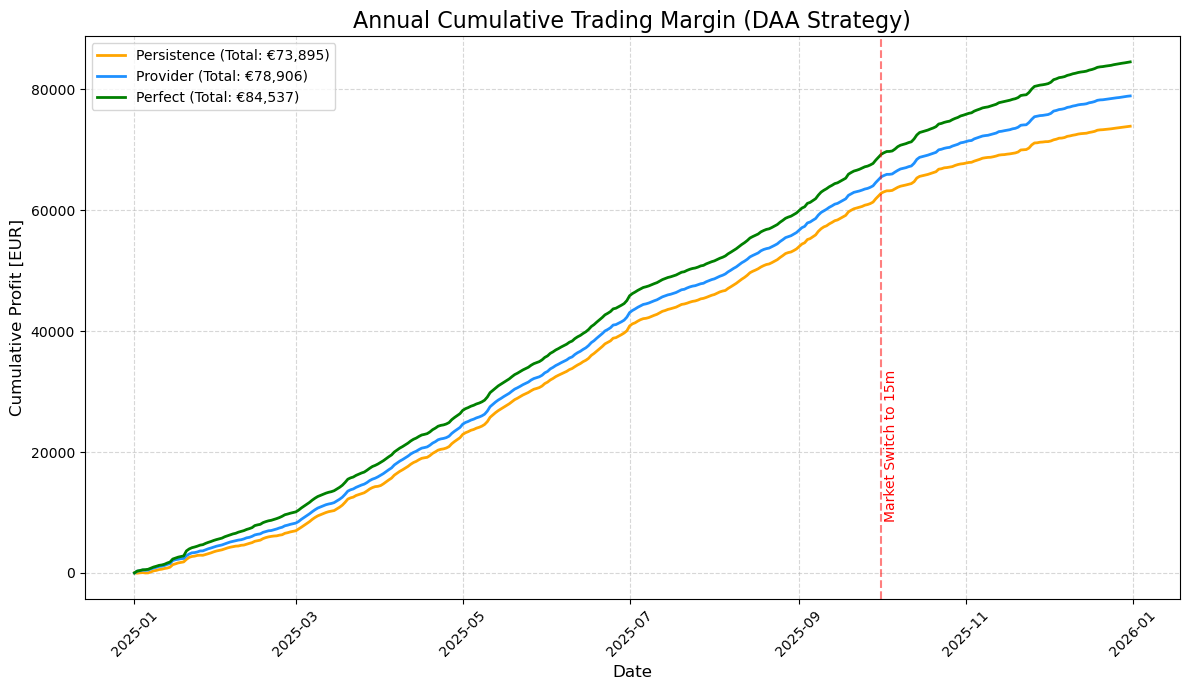

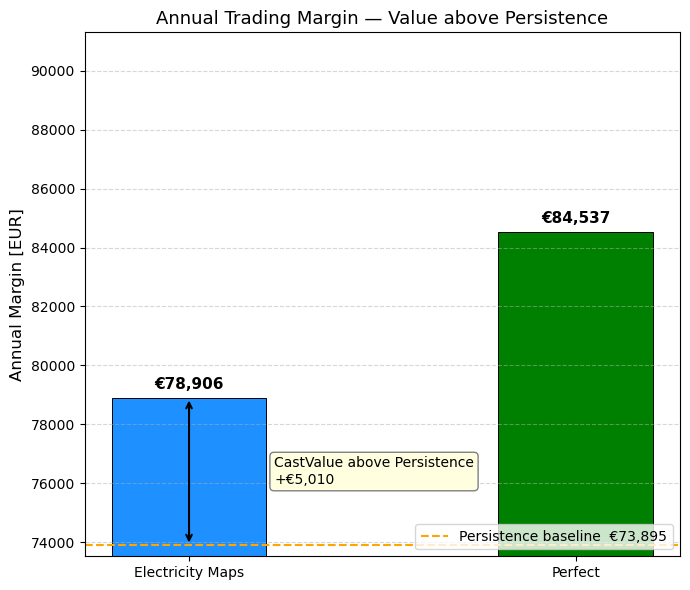

In [1]:
import numpy as np
import pandas as pd
from DAA_optimizer import Optimizer
import matplotlib.pyplot as plt

# 1. Load data
df = pd.read_csv("master_energy_data_v1.csv")

# --- NEW: Ensure timestamps are datetime objects ---
df['timestamp_utc'] = pd.to_datetime(df['timestamp_utc'])
CUTOFF_DATE = pd.Timestamp('2025-10-01', tz='UTC')

# 1. INITIALIZE the optimizer 
solverpath_exe = "/opt/anaconda3/bin/glpsol" 
opt = Optimizer(solverpath_exe)

# 2. Setup Indexing
num_days = len(df) // 96
df['day_index'] = np.repeat(np.arange(1, num_days + 1), 96)

# 3. Parameters
POWER_CAP_MW = 1.0
ENERGY_CAP_MWH = 2.0
N_CYCLES_PER_DAY = 1.0

SCENARIOS = {
    "Persistence": {"daa_f": "daa_persistence_forecast"},
    "Provider":    {"daa_f": "daa_provider_forecast"},
    "Perfect":      {"daa_f": "daa_actuals"}
}

results = []

import matplotlib.pyplot as plt

# --- UPDATED 5. Run the Backtest & Track Daily Profits ---
daily_margins_tracking = {sc: [] for sc in SCENARIOS.keys()}

for sc_name, cols in SCENARIOS.items():
    annual_profit = 0
    print(f"Running Scenario: {sc_name}...")
    
    for d in range(1, num_days + 1):
        day_data = df[df['day_index'] == d]
        first_timestamp = day_data['timestamp_utc'].iloc[0]
        current_res = '1h' if first_timestamp < CUTOFF_DATE else '15m'
        
        f_vec = {"daa": day_data[cols["daa_f"]].tolist()}
        a_vec = {"daa": day_data["daa_actuals"].tolist()}
        
        out = opt.run_day(f_vec, a_vec, POWER_CAP_MW, ENERGY_CAP_MWH, N_CYCLES_PER_DAY, resolution=current_res)
        
        # Store for cumulative plotting
        daily_margins_tracking[sc_name].append(out["profit_total"])
        annual_profit += out["profit_total"]
    
    results.append({"Scenario": sc_name, "Annual Margin": annual_profit})

# --- 6. Build Results DataFrame ---
results_df = pd.DataFrame(results)
persistence_margin = results_df.loc[results_df['Scenario'] == 'Persistence', 'Annual Margin'].values[0]
provider_margin    = results_df.loc[results_df['Scenario'] == 'Provider',    'Annual Margin'].values[0]
provider_vs_persistence = provider_margin - persistence_margin

# --- 7. Plotting the Cumulative Margin ---
plt.figure(figsize=(12, 7))

# Get unique dates for the X-axis
dates = df['timestamp_utc'].dt.date.unique()

# Define specific colors for consistency
colors = {"Persistence": "orange", "Provider": "dodgerblue", "Perfect": "green"}

for sc_name, daily_profits in daily_margins_tracking.items():
    cumulative_profit = np.cumsum(daily_profits)
    plt.plot(dates, cumulative_profit, label=f"{sc_name} (Total: €{cumulative_profit[-1]:,.0f})", 
             color=colors.get(sc_name), linewidth=2)

# Highlight the Oct 1st Market Switch
plt.axvline(pd.Timestamp('2025-10-01'), color='red', linestyle='--', alpha=0.5)
plt.text(pd.Timestamp('2025-10-02'), plt.ylim()[1]*0.1, 'Market Switch to 15m', color='red', rotation=90)

plt.title("Annual Cumulative Trading Margin (DAA Strategy)", fontsize=16)
plt.ylabel("Cumulative Profit [EUR]", fontsize=12)
plt.xlabel("Date", fontsize=12)
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=10)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- 8. Annual Results Bar Chart (value above persistence) ---
perfect_margin = results_df.loc[results_df['Scenario'] == 'Perfect', 'Annual Margin'].values[0]
cost_of_error  = perfect_margin - provider_margin

scenario_names = ['Electricity Maps', 'Perfect']
annual_margins = [provider_margin, perfect_margin]
bar_colors     = ['dodgerblue', 'green']

y_min = persistence_margin * 0.995
y_max = perfect_margin * 1.08

fig, ax = plt.subplots(figsize=(7, 6))
bars = ax.bar(scenario_names, annual_margins, color=bar_colors, width=0.4,
              edgecolor='black', linewidth=0.7, bottom=0)

# Persistence baseline
ax.axhline(persistence_margin, color='orange', linestyle='--', linewidth=1.5, label=f'Persistence baseline  €{persistence_margin:,.0f}')

# Value labels on each bar
for bar, val in zip(bars, annual_margins):
    ax.text(bar.get_x() + bar.get_width() / 2, val + (y_max - y_min) * 0.01,
            f'€{val:,.0f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Arrow: CastValue above Persistence (Electricity Maps bar vs persistence baseline)
castvalue = provider_margin - persistence_margin
ax.annotate('', xy=(0, provider_margin), xytext=(0, persistence_margin),
            arrowprops=dict(arrowstyle='<->', color='black', lw=1.5))
ax.text(0.22, (provider_margin + persistence_margin) / 2,
        f'CastValue above Persistence\n+€{castvalue:,.0f}',
        ha='left', va='center', fontsize=10, color='black',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', edgecolor='gray'))

ax.set_title('Annual Trading Margin — Value above Persistence', fontsize=13)
ax.set_ylabel('Annual Margin [EUR]', fontsize=12)
ax.set_ylim(y_min, y_max)
ax.legend(loc='lower right', fontsize=10)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


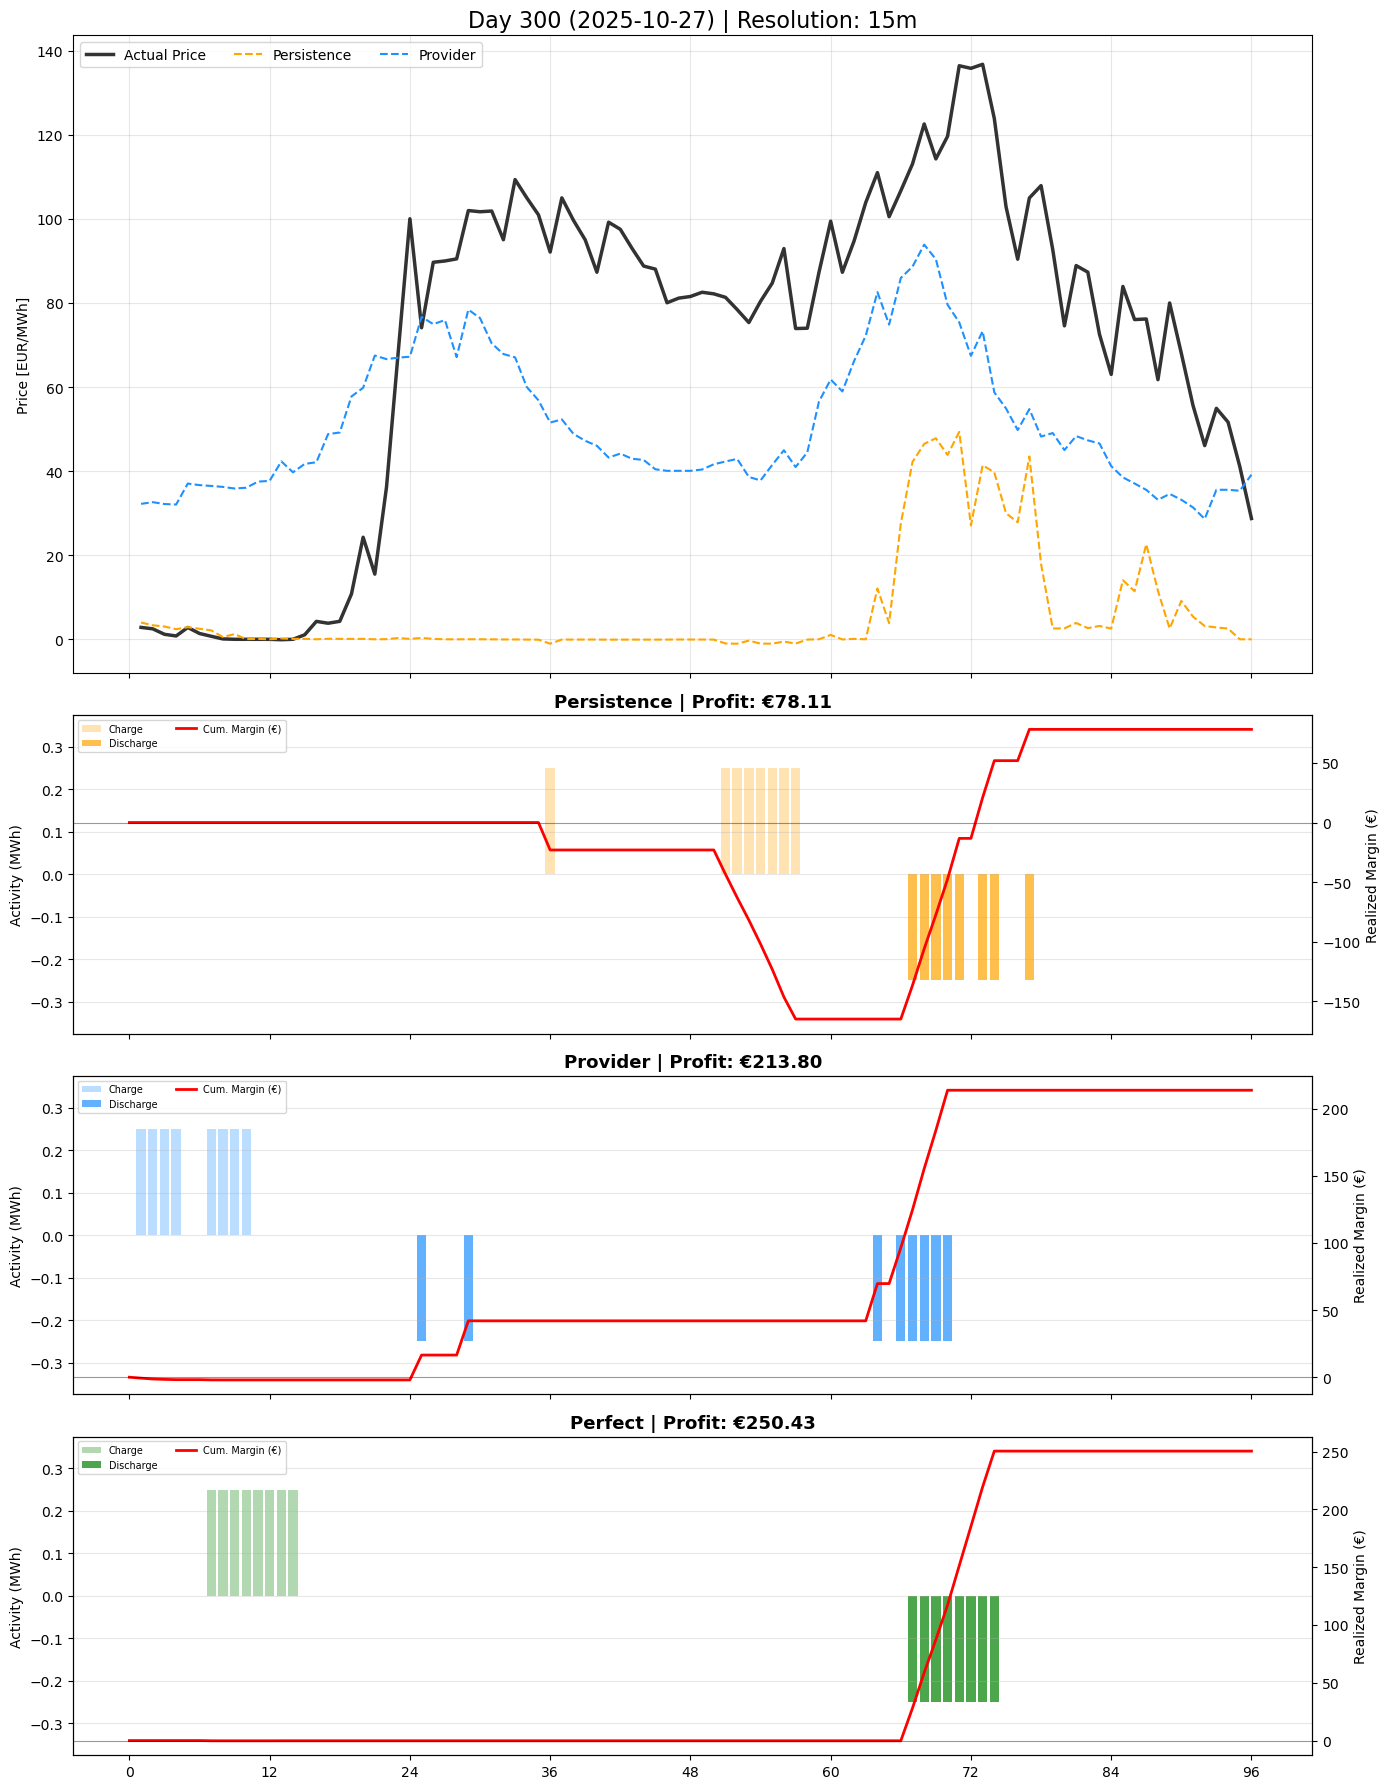

In [2]:
import matplotlib.pyplot as plt
import numpy as np

def plot_comparison(day_idx):
    """
    Visualizes price forecasts vs actuals, dispatch decisions, 
    and cumulative margins for 3 scenarios.
    """
    # 1. Prepare Day Data
    day_data = df[df['day_index'] == day_idx].copy()
    if day_data.empty:
        print(f"Error: Day index {day_idx} contains no data.")
        return

    first_ts = day_data['timestamp_utc'].iloc[0]
    res = '1h' if first_ts < CUTOFF_DATE else '15m'
    
    # Ensure exactly 96 points (1 day)
    actual_prices = day_data["daa_actuals"].values[:96]
    
    plot_scenarios = {
        "Persistence": day_data["daa_persistence_forecast"].values[:96],
        "Provider":    day_data["daa_provider_forecast"].values[:96],
        "Perfect":     actual_prices
    }
    
    results_cache = {}
    power_factor = POWER_CAP_MW / 4.0

    # 2. Run optimizations
    for name, price_vec in plot_scenarios.items():
        try:
            # Optimize to get charge/discharge schedules
            soc, cha, dis = opt.step1_optimize_daa(
                n_cycles=int(N_CYCLES_PER_DAY),
                energy_cap=ENERGY_CAP_MWH,
                power_cap=POWER_CAP_MW,
                daa_price_vector=list(price_vec),
                resolution=res
            )
            
            cha = np.array(cha)[:96]
            dis = np.array(dis)[:96]
            
            net_flow = dis - cha # Positive = Discharge (Revenue)
            margin_per_step = net_flow * actual_prices * power_factor
            
            results_cache[name] = {
                "cha": cha,
                "dis": dis,
                "cum_margin": np.cumsum(margin_per_step)
            }
        except Exception as e:
            print(f"Optimization failed for {name} on day {day_idx}: {e}")
            return

    # 3. Setup Plotting
    x_bars = np.arange(1, 97)
    x_lines = np.arange(0, 97)
    
    plt.close('all') 
    fig, axs = plt.subplots(4, 1, figsize=(14, 18), sharex=True, 
                            gridspec_kw={'height_ratios': [2, 1, 1, 1]})
    
    # --- Subplot 1: Price Comparison ---
    axs[0].plot(x_bars, actual_prices, color='black', linewidth=2.5, label='Actual Price', alpha=0.8)
    axs[0].plot(x_bars, plot_scenarios["Persistence"], '--', color='orange', label='Persistence')
    axs[0].plot(x_bars, plot_scenarios["Provider"], '--', color='dodgerblue', label='Provider')
    axs[0].set_title(f"Day {day_idx} ({first_ts.date()}) | Resolution: {res}", fontsize=16)
    axs[0].set_ylabel("Price [EUR/MWh]")
    axs[0].legend(loc='upper left', ncol=3)
    axs[0].grid(True, alpha=0.3)

    # --- Subplots 2-4: Decisions & Realized Margins ---
    scenario_order = ["Persistence", "Provider", "Perfect"]
    colors = ["orange", "dodgerblue", "green"]
    
    for i, name in enumerate(scenario_order):
        ax = axs[i+1]
        data = results_cache[name]
        
        # A. Draw Charge/Discharge Bars
        ax.bar(x_bars, data["cha"] * power_factor, color=colors[i], alpha=0.3, label='Charge')
        ax.bar(x_bars, -data["dis"] * power_factor, color=colors[i], alpha=0.7, label='Discharge')
        
        ax.set_ylim(-power_factor * 1.5, power_factor * 1.5)
        ax.set_ylabel("Activity (MWh)")
        ax.set_title(f"{name} | Profit: €{data['cum_margin'][-1]:.2f}", fontsize=13, fontweight='bold')
        ax.grid(axis='y', alpha=0.3)

        # B. Realized Margin (Twin Axis)
        ax_sec = ax.twinx()
        
        # Prepend 0 to ensure margin starts at midnight (0,0)
        margin_plot = np.zeros(97)
        margin_plot[1:] = data["cum_margin"]
        
        ax_sec.plot(x_lines, margin_plot, color='red', linewidth=2, label='Cum. Margin (€)')
        
        ax_sec.set_ylabel("Realized Margin (€)")
        ax_sec.axhline(0, color='black', linewidth=0.8, alpha=0.4)
        
        # Combine legends
        h1, l1 = ax.get_legend_handles_labels()
        h2, l2 = ax_sec.get_legend_handles_labels()
        ax.legend(h1 + h2, l1 + l2, loc='upper left', fontsize='x-small', ncol=2)

    plt.xticks([0, 12, 24, 36, 48, 60, 72, 84, 96])
    plt.xlabel("Interval (15-min)")
    plt.tight_layout()
    plt.show()

# Run Sample
plot_comparison(day_idx=300)

--- THE PARADOX DAYS ---
Bad Forecast, Good Capture:
  Day 15 (2025-01-15) | MAE: 78.72 | Lost: €1.03

Good Forecast, Bad Capture:
  Day 318 (2025-11-14) | MAE: 9.52 | Lost: €46.87


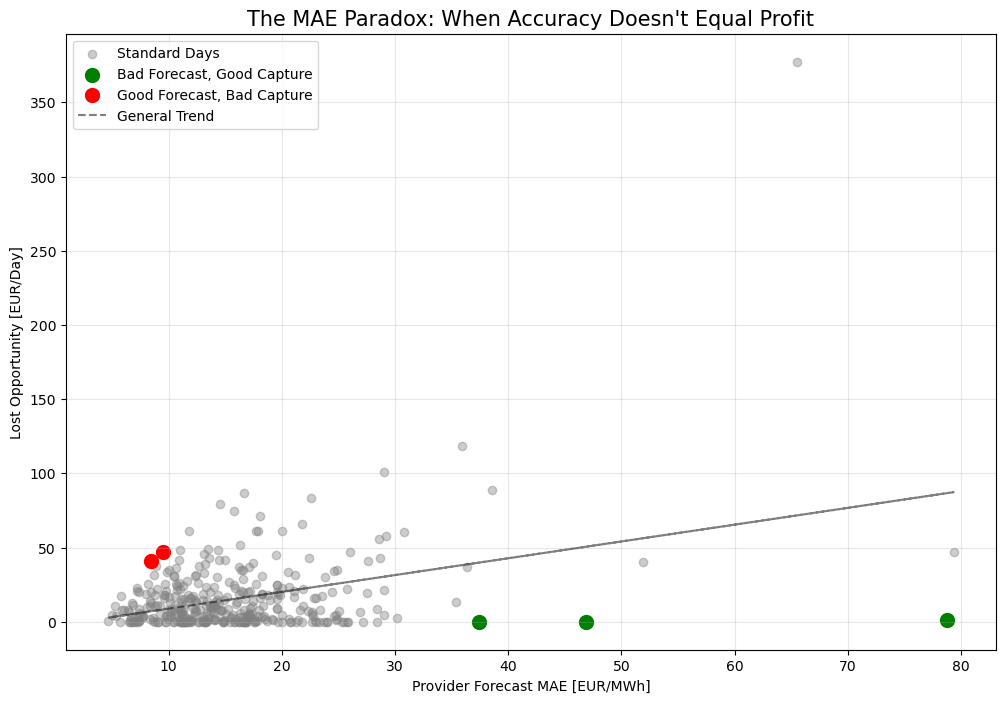

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 1. Calculate Daily MAE and Lost Opportunity
correlation_analysis = []

for d in range(1, num_days + 1):
    day_data = df[df['day_index'] == d]
    if day_data.empty:
        continue

    actuals = day_data['daa_actuals'].values
    prov_f = day_data['daa_provider_forecast'].values
    date = day_data['timestamp_utc'].iloc[0].date()

    # Calculate MAE for the day
    mae = np.mean(np.abs(prov_f - actuals))

    # Calculate Margins
    perf_margin = daily_margins_tracking["Perfect"][d-1]
    prov_margin = daily_margins_tracking["Provider"][d-1]
    lost_opp = perf_margin - prov_margin

    correlation_analysis.append({
        "day_index": d,
        "date": date,
        "mae": mae,
        "lost_opportunity": lost_opp,
        "perf_margin": perf_margin
    })

corr_df = pd.DataFrame(correlation_analysis)

# 2. Identify the Paradox Days
# Bad Forecast, Good Capture: High MAE but 0 Lost Opp (perfect capture despite bad prices)
# Good Forecast, Bad Capture: Low MAE but High Lost Opp (bad timing despite good prices)

high_mae_no_missed = corr_df[(corr_df['lost_opportunity'] <= corr_df['lost_opportunity'].quantile(0.25)) &
                             (corr_df['mae'] > corr_df['mae'].quantile(0.95))]

low_mae_high_missed = corr_df[(corr_df['mae'] < corr_df['mae'].quantile(0.25)) &
                              (corr_df['lost_opportunity'] > corr_df['lost_opportunity'].quantile(0.90))]

# 3. Print Results
print("--- THE PARADOX DAYS ---")
if not high_mae_no_missed.empty:
    best_high_mae = high_mae_no_missed.sort_values('mae', ascending=False).iloc[0]
    print(f"Bad Forecast, Good Capture:")
    print(f"  Day {best_high_mae['day_index']} ({best_high_mae['date']}) | MAE: {best_high_mae['mae']:.2f} | Lost: €{best_high_mae['lost_opportunity']:.2f}\n")

if not low_mae_high_missed.empty:
    worst_low_mae = low_mae_high_missed.sort_values('lost_opportunity', ascending=False).iloc[0]
    print(f"Good Forecast, Bad Capture:")
    print(f"  Day {worst_low_mae['day_index']} ({worst_low_mae['date']}) | MAE: {worst_low_mae['mae']:.2f} | Lost: €{worst_low_mae['lost_opportunity']:.2f}")

# 4. Plotting
plt.figure(figsize=(12, 8))
plt.scatter(corr_df['mae'], corr_df['lost_opportunity'], alpha=0.4, color='gray', label='Standard Days')

# Highlight Paradoxes
if not high_mae_no_missed.empty:
    plt.scatter(high_mae_no_missed['mae'], high_mae_no_missed['lost_opportunity'], color='green', s=100, label='Bad Forecast, Good Capture')
if not low_mae_high_missed.empty:
    plt.scatter(low_mae_high_missed['mae'], low_mae_high_missed['lost_opportunity'], color='red', s=100, label='Good Forecast, Bad Capture')

# Add Trend Line
m, b = np.polyfit(corr_df['mae'], corr_df['lost_opportunity'], 1)
plt.plot(corr_df['mae'], m*corr_df['mae'] + b, color='black', linestyle='--', alpha=0.5, label='General Trend')

plt.title("The MAE Paradox: When Accuracy Doesn't Equal Profit", fontsize=15)
plt.xlabel("Provider Forecast MAE [EUR/MWh]")
plt.ylabel("Lost Opportunity [EUR/Day]")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

--- Days with MAE > 70 ---
 day_index       date       mae  lost_opportunity
       329 2025-11-25 79.345037           46.6675
        15 2025-01-15 78.721632            1.0300


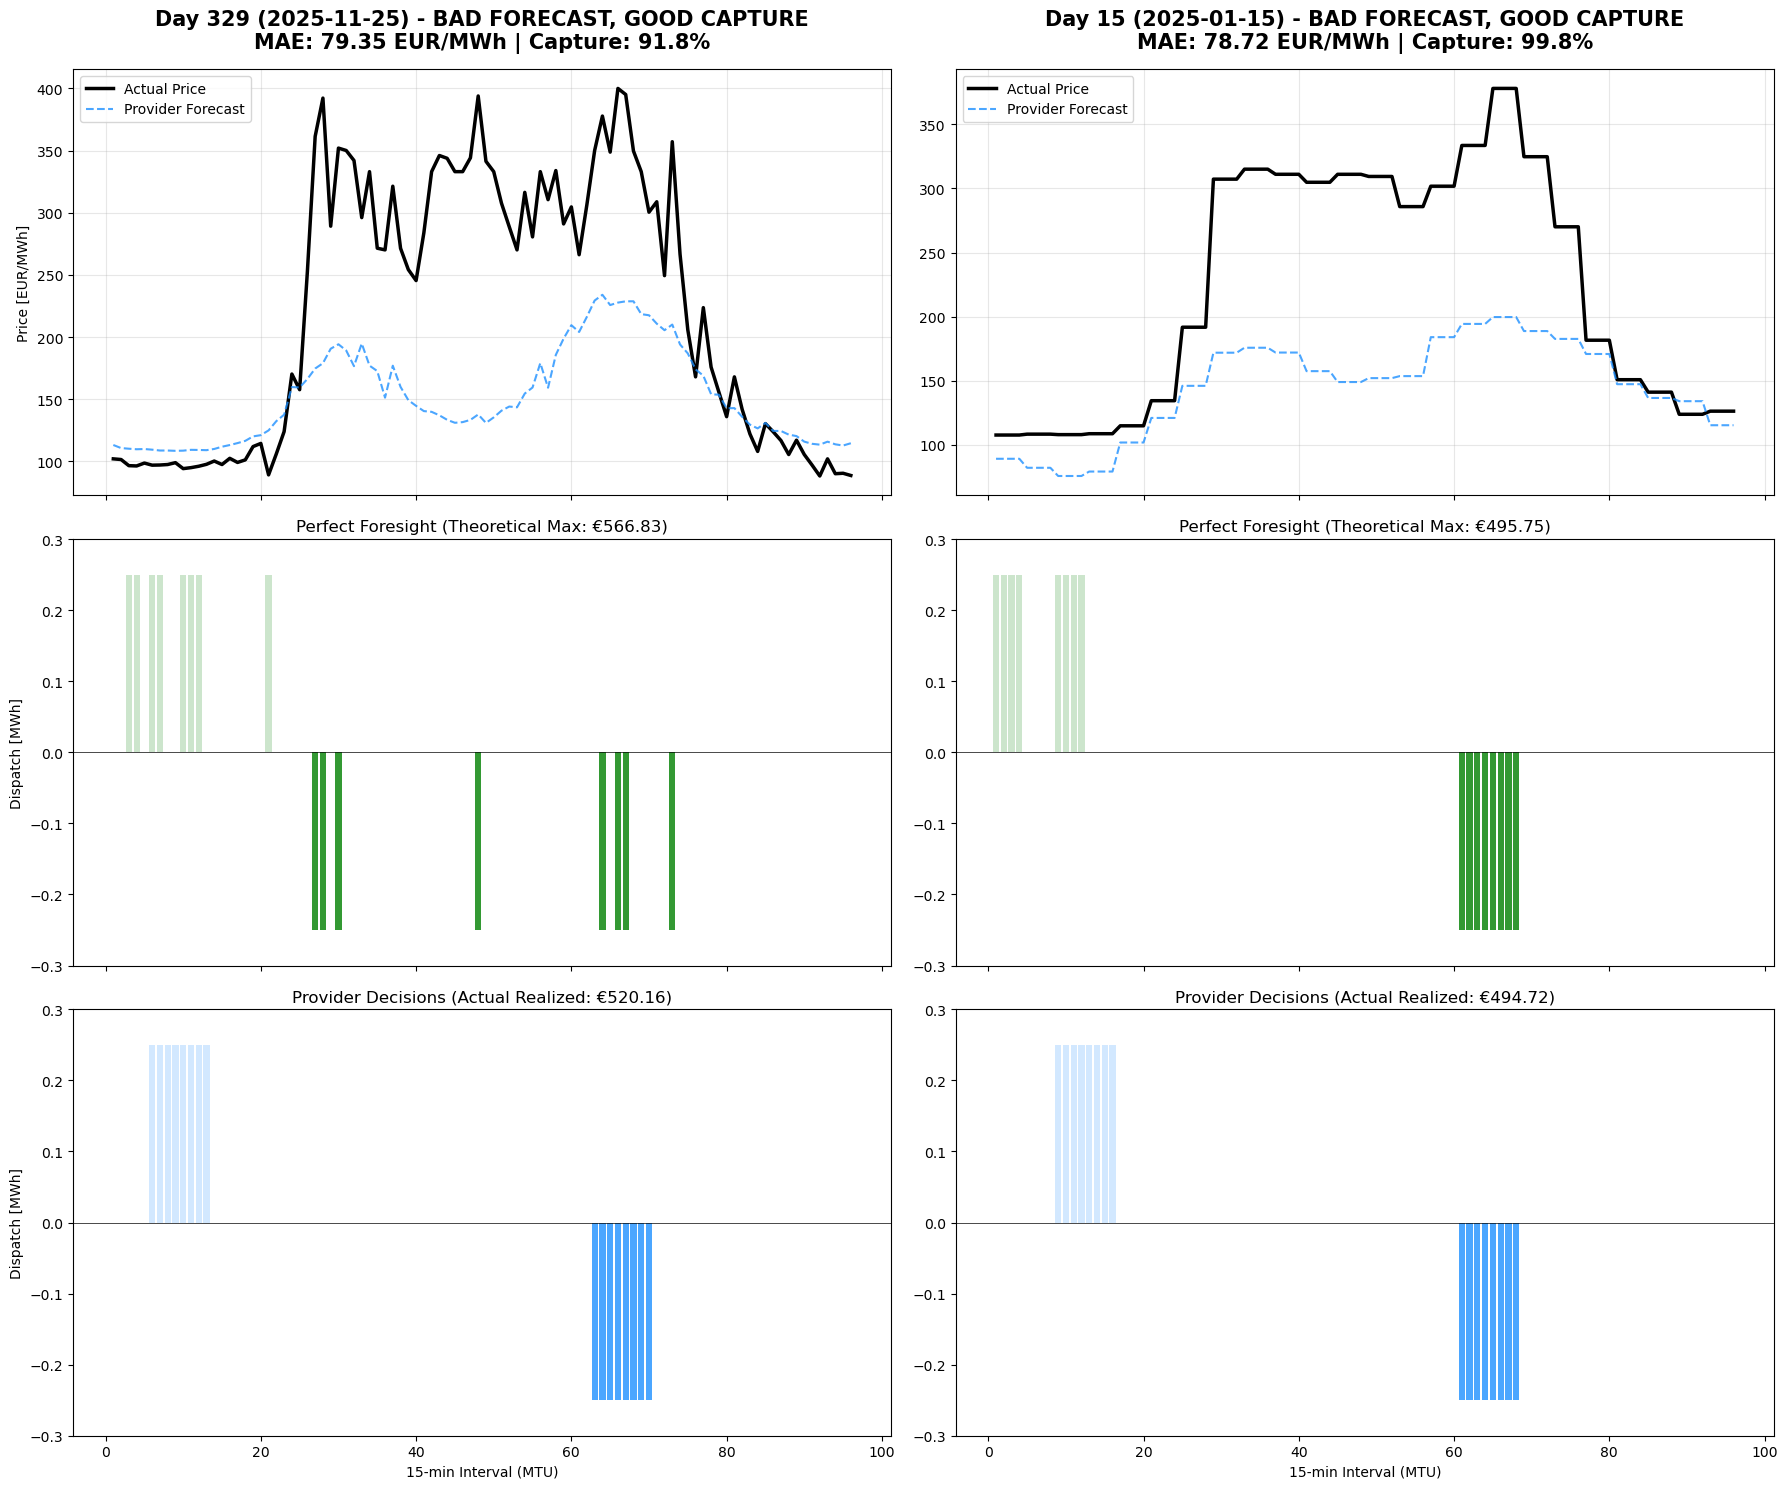

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def plot_paradox_deep_dive(day_idx_a, day_idx_b):
    """
    Performs a deep dive analysis on two specific days to compare 
    forecast accuracy (Vertical Error) vs. Dispatch Profit (Horizontal Error).
    """
    days = [day_idx_a, day_idx_b]
    fig, axs = plt.subplots(3, 2, figsize=(18, 15), sharex='col')
    
    power_factor = POWER_CAP_MW / 4.0
    x = np.arange(1, 97) # 96 intervals of 15-min

    for col, day_idx in enumerate(days):
        # 1. Extract Day Data
        day_data = df[df['day_index'] == day_idx].copy().iloc[:96]
        if day_data.empty:
            print(f"Day {day_idx} not found.")
            continue
            
        actuals = day_data["daa_actuals"].values
        provider_f = day_data["daa_provider_forecast"].values
        date = day_data['timestamp_utc'].iloc[0].date()
        
        # 2. Calculate Vertical Error (MAE)
        mae = np.mean(np.abs(actuals - provider_f))
        
        # 3. Run Optimizations for Perfect vs Provider
        scenarios = {"Perfect": actuals, "Provider": provider_f}
        results = {}
        res = '1h' if day_data['timestamp_utc'].iloc[0] < CUTOFF_DATE else '15m'
        
        for name, prices in scenarios.items():
            soc, cha, dis = opt.step1_optimize_daa(
                n_cycles=int(N_CYCLES_PER_DAY),
                energy_cap=ENERGY_CAP_MWH,
                power_cap=POWER_CAP_MW,
                daa_price_vector=list(prices),
                resolution=res
            )
            
            # Use actual prices to calculate the REAL money made by these decisions
            net_flow = np.array(dis[:96]) - np.array(cha[:96])
            daily_profit = np.sum(net_flow * actuals * power_factor)
            
            results[name] = {
                "cha": np.array(cha[:96]),
                "dis": np.array(dis[:96]),
                "profit": daily_profit
            }

        # Calculate capture rate (How much of the possible money did we get?)
        capture_rate = (results["Provider"]["profit"] / results["Perfect"]["profit"]) * 100

        # --- ROW 1: PRICE & FORECAST ---
        axs[0, col].plot(x, actuals, color='black', label='Actual Price', linewidth=2.5)
        axs[0, col].plot(x, provider_f, '--', color='dodgerblue', label='Provider Forecast', alpha=0.8)
        
        title_type = "BAD FORECAST, GOOD CAPTURE" if mae > 40 else "GOOD FORECAST, BAD CAPTURE"
        axs[0, col].set_title(f"Day {day_idx} ({date}) - {title_type}\nMAE: {mae:.2f} EUR/MWh | Capture: {capture_rate:.1f}%", 
                              fontsize=15, fontweight='bold', pad=15)
        axs[0, col].legend(loc='upper left')
        axs[0, col].grid(alpha=0.3)

        # --- ROW 2: PERFECT DISPATCH ---
        axs[1, col].bar(x, results["Perfect"]["cha"] * power_factor, color='green', alpha=0.2, label='Charge')
        axs[1, col].bar(x, -results["Perfect"]["dis"] * power_factor, color='green', alpha=0.8, label='Discharge')
        axs[1, col].set_title(f"Perfect Foresight (Theoretical Max: €{results['Perfect']['profit']:.2f})", fontsize=12)
        axs[1, col].set_ylim(-power_factor*1.2, power_factor*1.2)
        axs[1, col].axhline(0, color='black', linewidth=0.5)

        # --- ROW 3: PROVIDER DISPATCH ---
        axs[2, col].bar(x, results["Provider"]["cha"] * power_factor, color='dodgerblue', alpha=0.2)
        axs[2, col].bar(x, -results["Provider"]["dis"] * power_factor, color='dodgerblue', alpha=0.8)
        axs[2, col].set_title(f"Provider Decisions (Actual Realized: €{results['Provider']['profit']:.2f})", fontsize=12)
        axs[2, col].set_ylim(-power_factor*1.2, power_factor*1.2)
        axs[2, col].axhline(0, color='black', linewidth=0.5)

    # Global Labels
    axs[2, 0].set_xlabel("15-min Interval (MTU)")
    axs[2, 1].set_xlabel("15-min Interval (MTU)")
    axs[0, 0].set_ylabel("Price [EUR/MWh]")
    axs[1, 0].set_ylabel("Dispatch [MWh]")
    axs[2, 0].set_ylabel("Dispatch [MWh]")

    plt.tight_layout()
    plt.show()

# Dynamically find the two days with MAE > 70
extreme_mae_days = corr_df[corr_df['mae'] > 70].sort_values('mae', ascending=False)
print("--- Days with MAE > 70 ---")
print(extreme_mae_days[['day_index', 'date', 'mae', 'lost_opportunity']].to_string(index=False))

day_a, day_b = int(extreme_mae_days.iloc[0]['day_index']), int(extreme_mae_days.iloc[1]['day_index'])
plot_paradox_deep_dive(day_a, day_b)